In [1]:
from pathlib import Path
import re
import unicodedata

import pandas as pd


# Pasta que contém as subpastas das variáveis meteorológicas.
PASTA_DADOS = Path.cwd() / "dado_bruto" / "56_Ana Carolina de Oliveira Rodrigues"

VARIAVEIS = {
    "pressao": "pressão",
    "temperatura_ar": "temperatura_ar_horario_max_min",
    "umidade_relativa": "UR",
    "umidade_especifica": "UE",
    "temperatura_bulbo_umido": "tempbulboumido",
}

MESES = {
    "JAN": 1,
    "FEV": 2,
    "MAR": 3,
    "ABR": 4,
    "MAI": 5,
    "JUN": 6,
    "JUL": 7,
    "AGO": 8,
    "SET": 9,
    "OUT": 10,
    "NOV": 11,
    "DEZ": 12,
}


def remover_acentos(texto):
    """Remove acentos para comparar nomes de abas e pastas."""
    normalizado = unicodedata.normalize("NFKD", str(texto))
    return "".join(caractere for caractere in normalizado if not unicodedata.combining(caractere))


def encontrar_arquivos(variavel):
    """Retorna os arquivos anuais válidos, ordenados pelo ano."""
    pasta = PASTA_DADOS / variavel
    arquivos = []
    for arquivo in pasta.iterdir():
        if arquivo.name.startswith((".~lock", "~$")):
            continue
        if arquivo.suffix.lower() not in {".xls", ".xlsx"}:
            continue
        ano = re.fullmatch(r"(\d{4})", arquivo.stem)
        if ano:
            arquivos.append((int(ano.group(1)), arquivo))
    return sorted(arquivos)


def ler_mes(caminho_arquivo, aba, ano, mes):
    """Converte uma aba mensal dia x hora em data_hora x valor."""
    bruto = pd.read_excel(caminho_arquivo, sheet_name=aba, header=None)
    linha_dias = bruto.index[
        bruto.iloc[:, 0].astype(str).str.strip().str.upper().eq("H/D")
    ]
    if len(linha_dias) == 0:
        raise ValueError(f"Cabeçalho H/D não encontrado em {caminho_arquivo.name}, aba {aba!r}")

    linha_dias = linha_dias[0]
    dias = pd.to_numeric(bruto.iloc[linha_dias, 1:], errors="coerce")
    horas = pd.to_numeric(bruto.iloc[linha_dias + 1 :, 0], errors="coerce")
    valores = bruto.iloc[linha_dias + 1 :, 1:].copy()
    valores.index = horas
    valores.columns = dias
    valores = valores.loc[valores.index.notna(), valores.columns.notna()]

    tabela = (
        valores.rename_axis(index="hora", columns="dia")
        .reset_index()
        .melt(id_vars="hora", var_name="dia", value_name="valor")
    )
    tabela["hora"] = pd.to_numeric(tabela["hora"], errors="coerce")
    tabela["dia"] = pd.to_numeric(tabela["dia"], errors="coerce")
    tabela = tabela.dropna(subset=["hora", "dia"])
    tabela = tabela[tabela["hora"].between(1, 24)]

    ultimo_dia = pd.Period(year=ano, month=mes, freq="M").days_in_month
    tabela = tabela[tabela["dia"].between(1, ultimo_dia)]
    tabela["data_hora"] = (
        pd.to_datetime({"year": ano, "month": mes, "day": tabela["dia"].astype(int)})
        + pd.to_timedelta(tabela["hora"] - 1, unit="h")
    )
    return tabela[["data_hora", "valor"]].sort_values("data_hora").reset_index(drop=True)


def ler_ano(caminho_arquivo, ano):
    """Lê os 12 meses de um arquivo e devolve uma única tabela anual."""
    tabelas_mensais = []
    abas = pd.ExcelFile(caminho_arquivo).sheet_names
    for aba in abas:
        chave_mes = remover_acentos(aba).strip().upper()[:3]
        if chave_mes in MESES:
            tabelas_mensais.append(ler_mes(caminho_arquivo, aba, ano, MESES[chave_mes]))
    if len(tabelas_mensais) != 12:
        raise ValueError(f"{caminho_arquivo.name} possui {len(tabelas_mensais)} abas mensais; eram esperadas 12.")
    return pd.concat(tabelas_mensais, ignore_index=True).sort_values("data_hora").reset_index(drop=True)


# Estrutura final: tabelas[nome_da_variavel][ano] -> DataFrame com data_hora e valor.
tabelas = {}
for nome_variavel, pasta_variavel in VARIAVEIS.items():
    tabelas[nome_variavel] = {}
    for ano, arquivo in encontrar_arquivos(pasta_variavel):
        tabelas[nome_variavel][ano] = ler_ano(arquivo, ano)


# Resumo para conferir quantos anos e registros foram carregados.
resumo = pd.DataFrame(
    [
        {
            "variavel": variavel,
            "anos": len(tabelas[variavel]),
            "primeiro_ano": min(tabelas[variavel]),
            "ultimo_ano": max(tabelas[variavel]),
            "registros_primeiro_ano": len(tabelas[variavel][min(tabelas[variavel])]),
        }
        for variavel in tabelas
    ]
)
resumo

,variavel,anos,primeiro_ano,ultimo_ano,registros_primeiro_ano
0,pressao,31,1995,2025,8760
1,temperatura_ar,31,1995,2025,8760
2,umidade_relativa,31,1995,2025,8760
3,umidade_especifica,31,1995,2025,8760
4,temperatura_bulbo_umido,31,1995,2025,6570


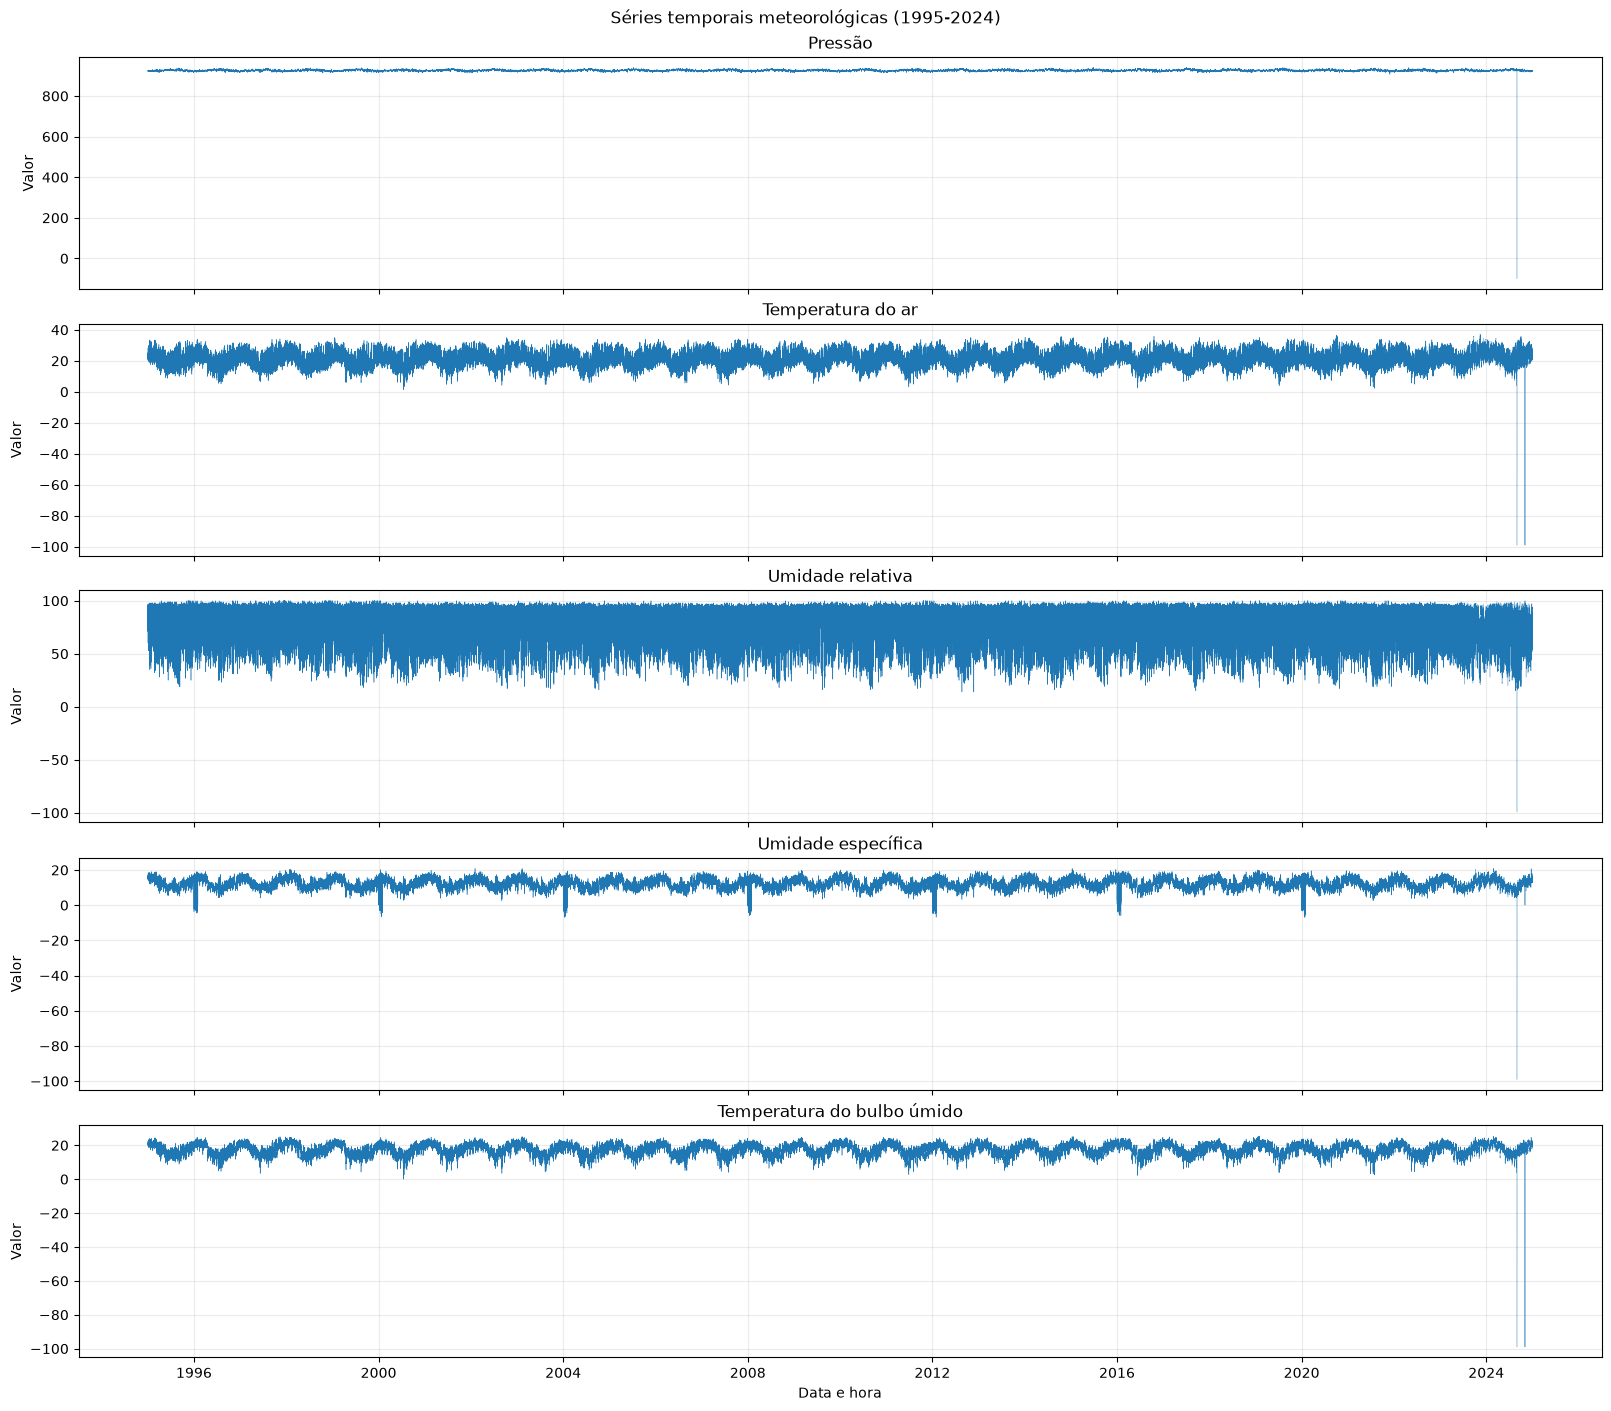

Período selecionado: 1995 a 2024
Total de anos: 30


In [2]:
import matplotlib.pyplot as plt


# Existem 31 arquivos comuns (1995-2025); a série solicitada usa os primeiros 30 anos.
anos_comuns = sorted(set.intersection(*(set(tabelas[variavel]) for variavel in tabelas)))
ANOS_SERIE = anos_comuns[:30]

if len(ANOS_SERIE) != 30:
    raise ValueError(f"Foram encontrados apenas {len(ANOS_SERIE)} anos comuns entre as variáveis.")


# Concatena os 30 DataFrames anuais de cada variável em uma série temporal contínua.
series_temporais = {}
for variavel in tabelas:
    series_temporais[variavel] = pd.concat(
        [tabelas[variavel][ano] for ano in ANOS_SERIE],
        ignore_index=True,
    ).sort_values("data_hora").reset_index(drop=True)


nomes_graficos = {
    "pressao": "Pressão",
    "temperatura_ar": "Temperatura do ar",
    "umidade_relativa": "Umidade relativa",
    "umidade_especifica": "Umidade específica",
    "temperatura_bulbo_umido": "Temperatura do bulbo úmido",
}

figura, eixos = plt.subplots(
    nrows=len(series_temporais),
    ncols=1,
    figsize=(16, 14),
    sharex=True,
    constrained_layout=True,
)

for eixo, (variavel, serie) in zip(eixos, series_temporais.items()):
    eixo.plot(serie["data_hora"], serie["valor"], linewidth=0.35)
    eixo.set_title(nomes_graficos.get(variavel, variavel))
    eixo.set_ylabel("Valor")
    eixo.grid(True, alpha=0.25)

eixos[-1].set_xlabel("Data e hora")
figura.suptitle(f"Séries temporais meteorológicas ({ANOS_SERIE[0]}-{ANOS_SERIE[-1]})")
plt.show()

print(f"Período selecionado: {ANOS_SERIE[0]} a {ANOS_SERIE[-1]}")
print(f"Total de anos: {len(ANOS_SERIE)}")

In [3]:
PASTA_SAIDA_CSV = Path.cwd() / "series_temporais_csv"
PASTA_SAIDA_CSV.mkdir(parents=True, exist_ok=True)

arquivos_csv = {}
for variavel, serie in series_temporais.items():
    caminho_csv = PASTA_SAIDA_CSV / f"{variavel}_{ANOS_SERIE[0]}_{ANOS_SERIE[-1]}.csv"
    serie.to_csv(caminho_csv, index=False, encoding="utf-8")
    arquivos_csv[variavel] = caminho_csv

resumo_exportacao = pd.DataFrame(
    [
        {
            "variavel": variavel,
            "arquivo": str(caminho_csv),
            "registros": len(series_temporais[variavel]),
        }
        for variavel, caminho_csv in arquivos_csv.items()
    ]
)
resumo_exportacao

,variavel,arquivo,registros
0,pressao,/home/ana/TCC/dados_estacao_iag/series_tempora...,262992
1,temperatura_ar,/home/ana/TCC/dados_estacao_iag/series_tempora...,263736
2,umidade_relativa,/home/ana/TCC/dados_estacao_iag/series_tempora...,262992
3,umidade_especifica,/home/ana/TCC/dados_estacao_iag/series_tempora...,273408
4,temperatura_bulbo_umido,/home/ana/TCC/dados_estacao_iag/series_tempora...,197244
